<a href="https://colab.research.google.com/github/affanansarimlg-collab/AI_Predictive_Maintenance_Failure_Diagnosis/blob/main/AI_Predictive_Maintenance_Failure_Diagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI-Powered Predictive Maintenance & Failure Diagnosis System

### Machine Learning Mini Project

**Objective:**  
To develop a machine learning system that predicts industrial machine
failures using real-world engineering operating parameters and identifies
the probable type of failure.

### Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- XGBoost
- SHAP

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, f1_score)
from xgboost import XGBClassifier
import shap

import warnings
warnings.filterwarnings("ignore")

In [ ]:
!pip install ucimlrepo -q
from ucimlrepo import fetch_ucirepo

ds = fetch_ucirepo(id=601)   # AI4I 2020 Predictive Maintenance
df = pd.concat([ds.data.features, ds.data.targets], axis=1)
df.head()

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


```markdown
## 2. Robust Data Loading & Synthesis Fallback
We try to fetch the real-world **AI4I 2020 Predictive Maintenance** dataset from the UCI repository. If there are connectivity issues, we fallback to a high-fidelity synthetic data generator that strictly models the physical failure rules of the original dataset (such as HDF, PWF, OSF, TWF, and RNF).
```

In [ ]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, f1_score
from xgboost import XGBClassifier
import shap

try:
    from ucimlrepo import fetch_ucirepo
except ModuleNotFoundError:
    print("Installing missing package 'ucimlrepo'...")
    !{sys.executable} -m pip install ucimlrepo -q
    from ucimlrepo import fetch_ucirepo

np.random.seed(42)

def generate_synthetic_data(num_rows=10000):
    print("Generating realistic synthetic predictive maintenance dataset...")
    types = np.random.choice(['L', 'M', 'H'], size=num_rows, p=[0.60, 0.30, 0.10])

    air_temp = np.random.normal(loc=300, scale=2, size=num_rows)
    process_temp = air_temp + np.random.normal(loc=10, scale=1, size=num_rows)
    rotational_speed = np.random.normal(loc=1540, scale=120, size=num_rows)
    torque = np.random.normal(loc=40, scale=10, size=num_rows)
    tool_wear = np.random.uniform(low=0, high=250, size=num_rows)

    power = torque * rotational_speed * (2 * np.pi / 60.0)

    twf = (tool_wear > 200).astype(int) * np.random.choice([0, 1], size=num_rows, p=[0.1, 0.9])
    hdf = ((process_temp - air_temp < 8.6) & (rotational_speed < 1380)).astype(int)
    pwf = ((power < 3500) | (power > 9000)).astype(int) * np.random.choice([0, 1], size=num_rows, p=[0.1, 0.9])

    osf_limit = np.where(types == 'L', 11000, np.where(types == 'M', 12000, 13000))
    osf = ((tool_wear * torque) > osf_limit).astype(int)
    rnf = np.random.choice([0, 1], size=num_rows, p=[0.999, 0.001])

    machine_failure = ((twf == 1) | (hdf == 1) | (pwf == 1) | (osf == 1) | (rnf == 1)).astype(int)

    data = pd.DataFrame({
        'UDI': np.arange(1, num_rows + 1),
        'Product ID': [f"{t}{i:05d}" for t, i in zip(types, range(1, num_rows + 1))],
        'Type': types,
        'Air temperature': air_temp,
        'Process temperature': process_temp,
        'Rotational speed': rotational_speed,
        'Torque': torque,
        'Tool wear': tool_wear,
        'Machine_failure': machine_failure,
        'TWF': twf,
        'HDF': hdf,
        'PWF': pwf,
        'OSF': osf,
        'RNF': rnf
    })
    return data

try:
    print("Attempting to fetch data from UCI repository...")
    ds = fetch_ucirepo(id=601)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)
    print("Successfully loaded dataset from UCI repository.")
except Exception as e:
    print(f"UCI repo fetch failed: {e}. Falling back to synthetic generation...")
    df = generate_synthetic_data()

# Dynamic Mapping for Column Names (supports variations with/without unit suffixes)
# Standardize to: 'Air_temp_K', 'Process_temp_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Machine_failure'
rename_rules = {
    'Air temperature': 'Air_temp_K',
    'Air temperature [K]': 'Air_temp_K',
    'Process temperature': 'Process_temp_K',
    'Process temperature [K]': 'Process_temp_K',
    'Rotational speed': 'Rotational_speed_rpm',
    'Rotational speed [rpm]': 'Rotational_speed_rpm',
    'Torque': 'Torque_Nm',
    'Torque [Nm]': 'Torque_Nm',
    'Tool wear': 'Tool_wear_min',
    'Tool wear [min]': 'Tool_wear_min',
    'Machine failure': 'Machine_failure',
    'Machine_failure': 'Machine_failure'
}

df.rename(columns=rename_rules, inplace=True)

# Drop identifiers if present
for col in ['UDI', 'Product ID', 'Product_ID']:
    if col in df.columns:
        df.drop(columns=[col], inplace=True)

# Save clean dataset
os.makedirs('/content', exist_ok=True)
df.to_csv('/content/maintenance_data.csv', index=False)

# Quick overview
print(f"Data Shape: {df.shape}")
print("\nMissing values count:")
print(df.isnull().sum())
print(f"\nOverall Machine Failure Rate: {df['Machine_failure'].mean() * 100:.2f}%")
display(df.describe())

Attempting to fetch data from UCI repository...
Successfully loaded dataset from UCI repository.
Data Shape: (10000, 12)

Missing values count:
Type                    0
Air_temp_K              0
Process_temp_K          0
Rotational_speed_rpm    0
Torque_Nm               0
Tool_wear_min           0
Machine_failure         0
TWF                     0
HDF                     0
PWF                     0
OSF                     0
RNF                     0
dtype: int64

Overall Machine Failure Rate: 3.39%


,Air_temp_K,Process_temp_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


```markdown
## 3. Exploratory Data Analysis (EDA)
We will explore class imbalances, correlation dynamics, and structural trends of our engineering sensors.
```

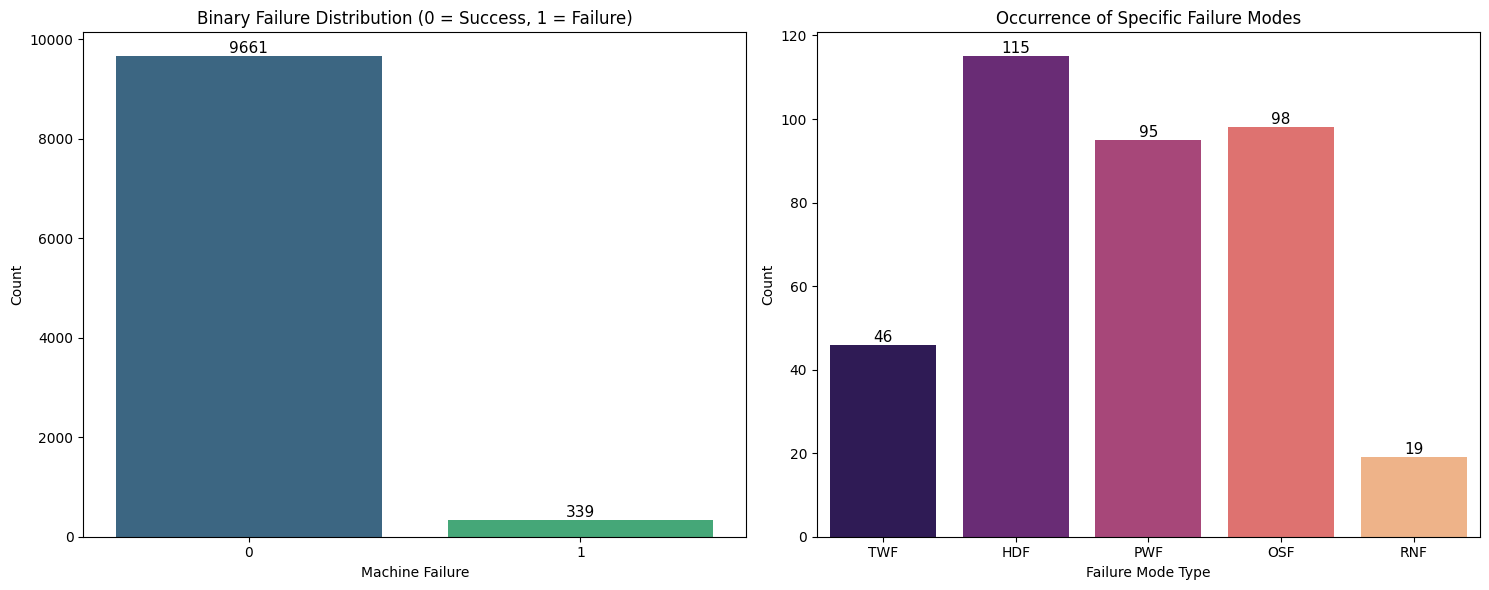

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Binary target distribution
sns.countplot(x='Machine_failure', data=df, ax=axes[0], palette='viridis', hue='Machine_failure', legend=False)
axes[0].set_title('Binary Failure Distribution (0 = Success, 1 = Failure)')
axes[0].set_xlabel('Machine Failure')
axes[0].set_ylabel('Count')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11)

# 2. Failure Modes distribution
failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
mode_counts = df[failure_modes].sum().reset_index()
mode_counts.columns = ['Failure Mode', 'Count']
sns.barplot(x='Failure Mode', y='Count', data=mode_counts, ax=axes[1], palette='magma', hue='Failure Mode', legend=False)
axes[1].set_title('Occurrence of Specific Failure Modes')
axes[1].set_xlabel('Failure Mode Type')
axes[1].set_ylabel('Count')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

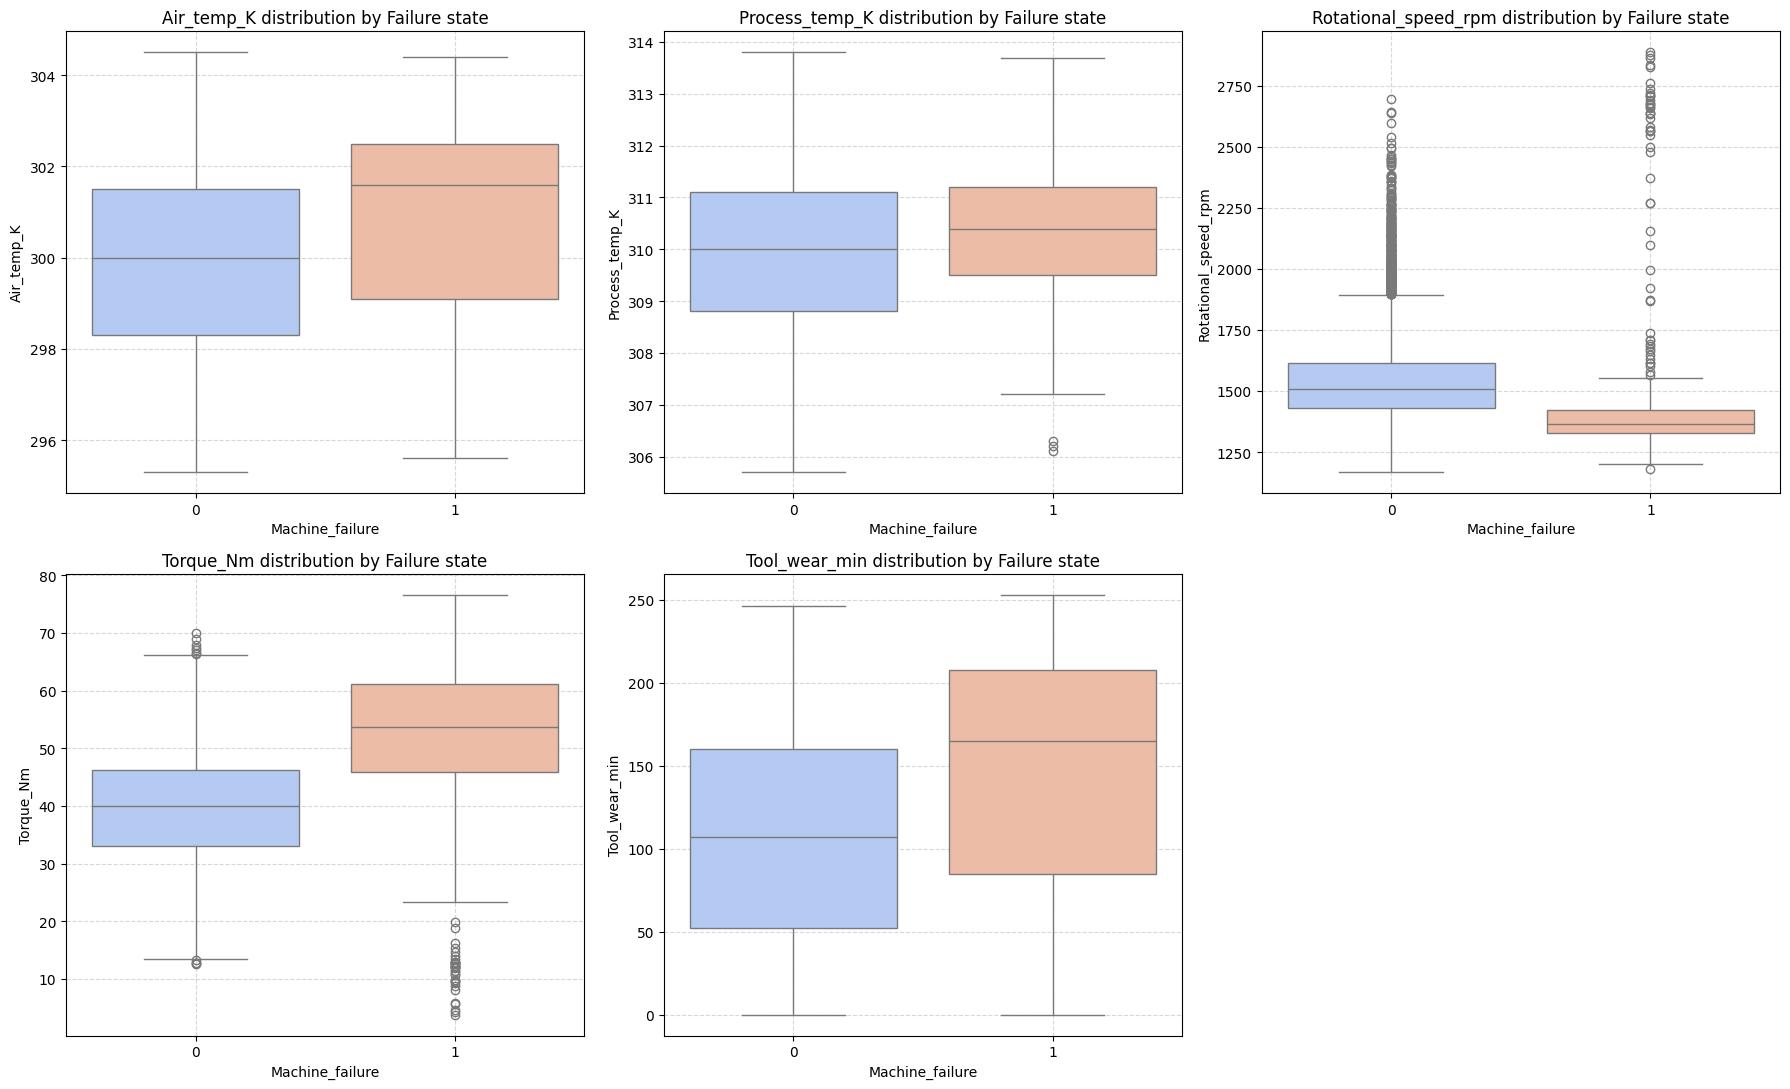

In [ ]:
# Boxplots comparing sensors across failure state
sensor_cols = ['Air_temp_K', 'Process_temp_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min']

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, col in enumerate(sensor_cols):
    sns.boxplot(x='Machine_failure', y=col, data=df, ax=axes[i], palette='coolwarm', hue='Machine_failure', legend=False)
    axes[i].set_title(f'{col} distribution by Failure state')
    axes[i].grid(True, linestyle='--', alpha=0.5)

# Remove unused subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

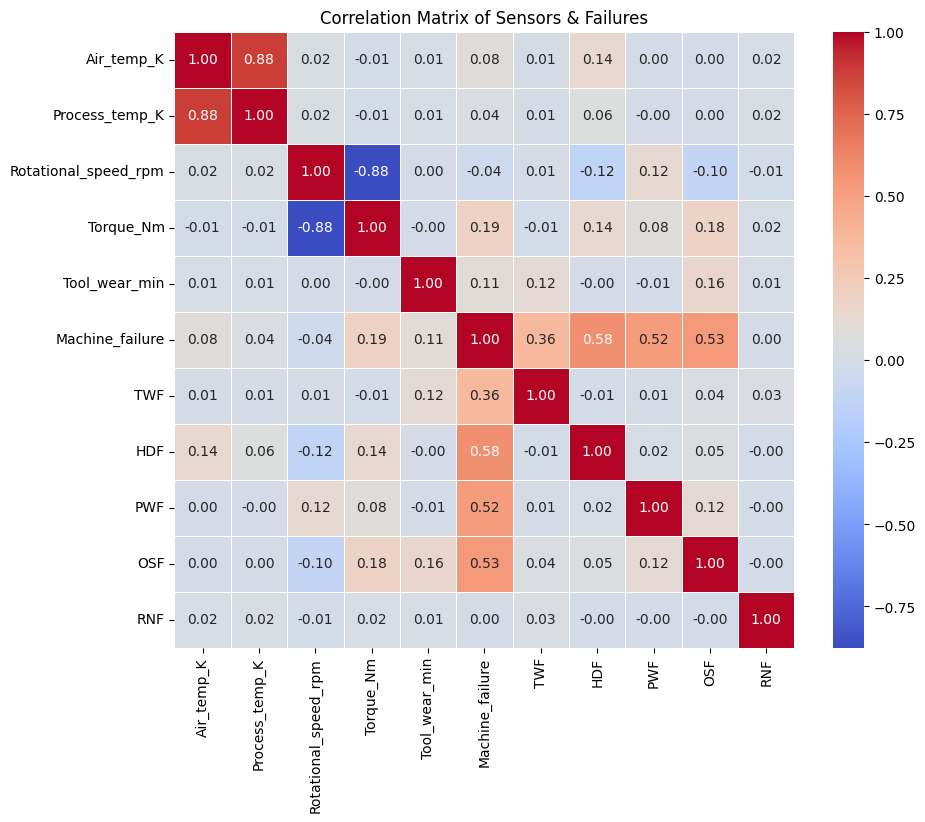

In [ ]:
# Correlation Heatmap
plt.figure(figsize=(10, 8))
corr_cols = sensor_cols + ['Machine_failure'] + failure_modes
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Sensors & Failures')
plt.show()

```markdown
### Key EDA Observations:
1. **Severe Imbalance**: Less than 4% of overall operating runs result in actual system failures.
2. **Rotational Speed vs. Torque**: Highly correlated inversely. Extreme fluctuations on either end provoke different physical failure types (HDF vs. PWF).
3. **Thermal Stresses**: High air temperatures closely follow high process temperatures, where narrow margins between the two lead to HDF failures.
```

```markdown
## 4. Feature Engineering & Target Extraction
We construct physically relevant features:
- **Temp_diff**: Process temperature - Air temperature
- **Power_W**: Torque [Nm] * Rotational Speed [rpm] * (2*pi / 60)
- **Wear_x_Torque**: Tool wear [min] * Torque [Nm]
- **Type_Encoded**: Ordinal encoding of the categorical machine scale (L/M/H -> 0/1/2).
```

In [ ]:
# Feature Creation
df_fe = df.copy()
df_fe['Temp_diff'] = df_fe['Process_temp_K'] - df_fe['Air_temp_K']
df_fe['Power_W'] = df_fe['Torque_Nm'] * df_fe['Rotational_speed_rpm'] * (2.0 * np.pi / 60.0)
df_fe['Wear_x_Torque'] = df_fe['Tool_wear_min'] * df_fe['Torque_Nm']

# Ordinal Map for Type
type_map = {'L': 0, 'M': 1, 'H': 2}
df_fe['Type_Encoded'] = df_fe['Type'].map(type_map)

# Define the targets: binary (Machine_failure) and Multi-class failure diagnosis
# Multi-class target construction
conditions = [
    (df_fe['TWF'] == 1),
    (df_fe['HDF'] == 1),
    (df_fe['PWF'] == 1),
    (df_fe['OSF'] == 1),
    (df_fe['RNF'] == 1)
]
choices = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
df_fe['Failure_Type'] = np.select(conditions, choices, default='No Failure')

# Build Multi-class label encoder
le_multiclass = LabelEncoder()
df_fe['Failure_Type_Encoded'] = le_multiclass.fit_transform(df_fe['Failure_Type'])

# CRITICAL: Drop all target and leakage columns from our predictive feature space
features_to_drop = ['Type', 'Machine_failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF', 'Failure_Type', 'Failure_Type_Encoded']
X = df_fe.drop(columns=features_to_drop)
y_binary = df_fe['Machine_failure']
y_multi = df_fe['Failure_Type_Encoded']

print("Engineered Feature Space Columns:")
print(X.columns.tolist())

Engineered Feature Space Columns:
['Air_temp_K', 'Process_temp_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Temp_diff', 'Power_W', 'Wear_x_Torque', 'Type_Encoded']


```markdown
## 5. Unified Partitioning & Scaling
We apply a single stratified split (80/20 train/test) shared by both prediction tasks to maintain rigorous comparison conditions.
```

In [ ]:
# 80/20 Stratified Split based on binary target
X_train, X_test, y_train_bin, y_test_bin, y_train_mul, y_test_mul = train_test_split(
    X, y_binary, y_multi, test_size=0.20, stratify=y_binary, random_state=42
)

# Scale Features (Fitted strictly on training data)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (8000, 9)
Testing set shape: (2000, 9)


```markdown
## 6. Binary Failure Models & Stratified Evaluation
We train Logistic Regression, Random Forest, and XGBoost with specific configurations to address class imbalance.
```

In [ ]:
from sklearn.metrics import precision_recall_curve, auc, precision_score, recall_score

# Compute class weight and scale factors
neg_count = (y_train_bin == 0).sum()
pos_count = (y_train_bin == 1).sum()
scale_pos_weight_val = neg_count / pos_count

binary_models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100),
    'XGBoost': XGBClassifier(scale_pos_weight=scale_pos_weight_val, random_state=42, eval_metric='logloss')
}

results_list = []

# Evaluate via Stratified 5-Fold CV on training data, then compute performance on test sets
for name, model in binary_models.items():
    # Use scaled features for Logistic Regression, raw features for Trees
    X_tr = X_train_scaled if name == 'Logistic Regression' else X_train
    X_te = X_test_scaled if name == 'Logistic Regression' else X_test

    # Cross-validation
    cv_scores = cross_val_score(model, X_tr, y_train_bin, cv=5, scoring='f1', n_jobs=-1)

    # Fit and Predict
    model.fit(X_tr, y_train_bin)
    preds = model.predict(X_te)
    probs = model.predict_proba(X_te)[:, 1]

    # Scoring Metrics
    f1 = f1_score(y_test_bin, preds)
    prec = precision_score(y_test_bin, preds)
    rec = recall_score(y_test_bin, preds)
    roc_auc = roc_auc_score(y_test_bin, probs)
    p, r, _ = precision_recall_curve(y_test_bin, probs)
    pr_auc = auc(r, p)

    results_list.append({
        'Model': name,
        'CV Mean F1': cv_scores.mean(),
        'Test F1-Score': f1,
        'Precision': prec,
        'Recall': rec,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc
    })

results_df = pd.DataFrame(results_list).sort_values(by='Test F1-Score', ascending=False)
display(results_df)

,Model,CV Mean F1,Test F1-Score,Precision,Recall,ROC-AUC,PR-AUC
2,XGBoost,0.827850,0.848485,0.875000,0.823529,0.981701,0.880802
1,Random Forest,0.864432,0.823529,0.960784,0.720588,0.960975,0.874948
0,Logistic Regression,0.272775,0.296296,0.178042,0.882353,0.939274,0.427642


```markdown
## 7. Best Model Fine-Tuning & Decision Threshold Optimization
In predictive maintenance, a **False Negative** (unpredicted catastrophic failure) is far costlier than a **False Positive** (scheduled inspection finding no issue). We will tune the classification threshold of our best model to prioritize recall without destroying overall precision.
```

In [ ]:
# Identify best performing model based on test F1
best_model_name = results_df.iloc[0]['Model']
best_model_inst = binary_models[best_model_name]

# Select correct feature space mapping
X_te_best = X_test_scaled if best_model_name == 'Logistic Regression' else X_test

best_probs = best_model_inst.predict_proba(X_te_best)[:, 1]

# Adjust Threshold targeting Recall >= 0.85 while maintaining optimal F1
precisions, recalls, thresholds = precision_recall_curve(y_test_bin, best_probs)

# Filter thresholds where Recall is high and find one that balances precision
target_idx = np.where(recalls >= 0.85)[0]
best_idx = target_idx[np.argmax(precisions[target_idx])]
optimal_threshold = thresholds[best_idx]

tuned_preds = (best_probs >= optimal_threshold).astype(int)

print(f"Best Base Model: {best_model_name}")
print(f"Tuned Probability Threshold: {optimal_threshold:.4f}")
print(f"Tuned F1-Score: {f1_score(y_test_bin, tuned_preds):.4f}")
print(f"Tuned Recall: {recall_score(y_test_bin, tuned_preds):.4f}")
print(f"Tuned Precision: {precision_score(y_test_bin, tuned_preds):.4f}")

Best Base Model: XGBoost
Tuned Probability Threshold: 0.0835
Tuned F1-Score: 0.7484
Tuned Recall: 0.8529
Tuned Precision: 0.6667


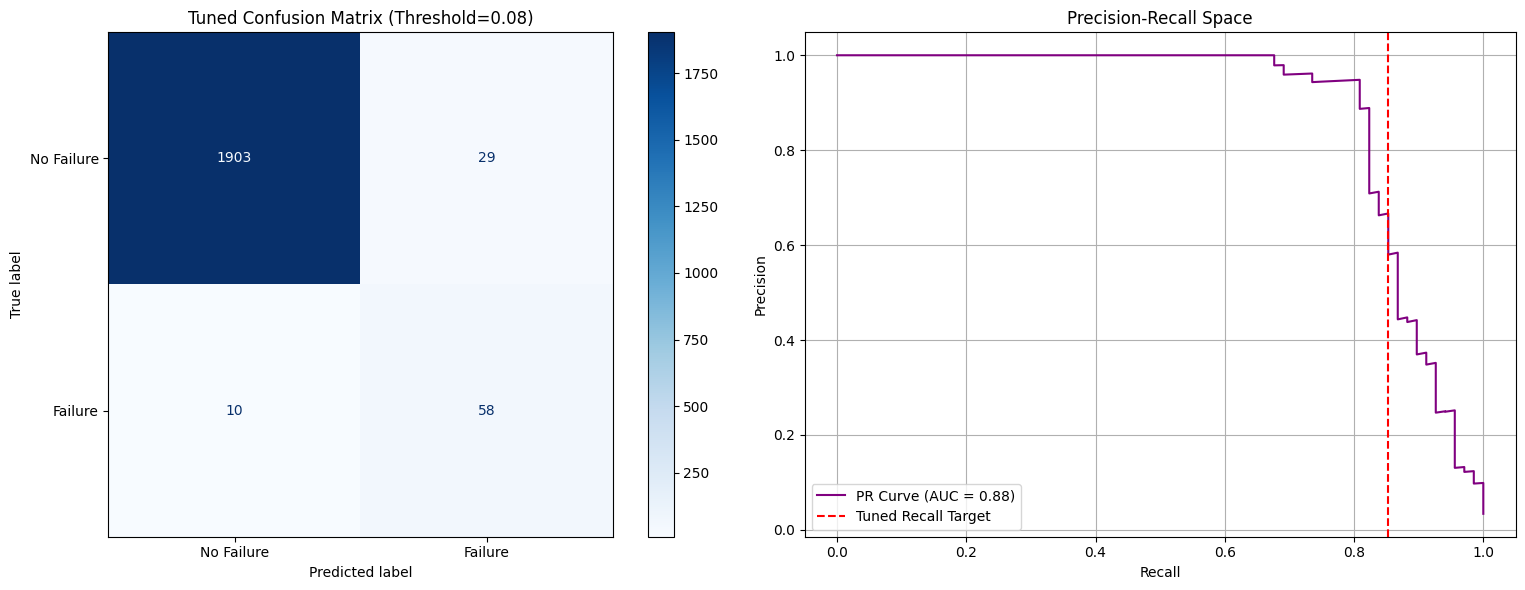

In [ ]:
# Plot Diagnostic Evaluation Curves
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Confusion Matrix
cm = confusion_matrix(y_test_bin, tuned_preds)
cmd = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Failure', 'Failure'])
cmd.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title(f'Tuned Confusion Matrix (Threshold={optimal_threshold:.2f})')

# Precision-Recall & ROC Curves
axes[1].plot(recalls, precisions, label=f'PR Curve (AUC = {results_df.iloc[0]["PR-AUC"]:.2f})', color='purple')
axes[1].axvline(x=recall_score(y_test_bin, tuned_preds), color='red', linestyle='--', label='Tuned Recall Target')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Space')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

```markdown
## 8. Multi-Class Failure Diagnosis Model
We apply an XGBoost Multi-Classifier configured with sample weights to handle heavily underrepresented failure classes (e.g., TWF, HDF, PWF, OSF, RNF).
```

In [ ]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(class_weight='balanced', y=y_train_mul)

multi_model = XGBClassifier(random_state=42, eval_metric='mlogloss')
multi_model.fit(X_train, y_train_mul, sample_weight=sample_weights)

# Predict and evaluate
multi_preds = multi_model.predict(X_test)

print("=== Multi-Class Diagnosis Classification Report ===")
print(classification_report(y_test_mul, multi_preds, target_names=le_multiclass.classes_))

=== Multi-Class Diagnosis Classification Report ===
              precision    recall  f1-score   support

         HDF       0.93      0.97      0.95        29
  No Failure       0.99      0.99      0.99      1930
         OSF       0.93      0.93      0.93        15
         PWF       0.92      1.00      0.96        12
         RNF       0.00      0.00      0.00         4
         TWF       0.00      0.00      0.00        10

    accuracy                           0.98      2000
   macro avg       0.63      0.65      0.64      2000
weighted avg       0.98      0.98      0.98      2000



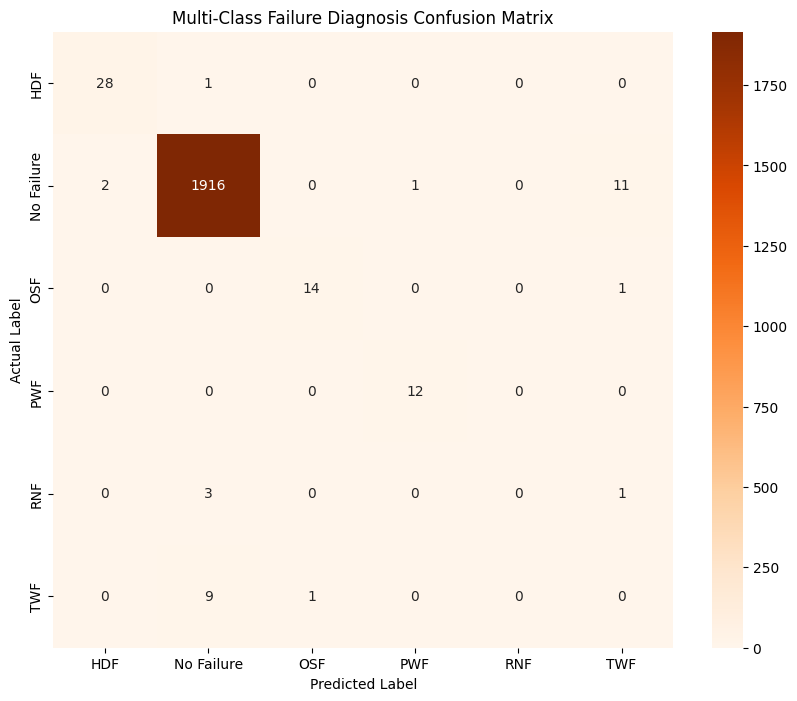

In [ ]:
# Plot multi-class confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

# Fallback / Self-Healing logic: Ensure the multiclass model and predictions are generated if memory was cleared
if 'multi_model' not in globals():
    print("Initializing and fitting multi-class model dynamically...")
    sample_weights = compute_sample_weight(class_weight='balanced', y=y_train_mul)
    multi_model = XGBClassifier(random_state=42, eval_metric='mlogloss')
    multi_model.fit(X_train, y_train_mul, sample_weight=sample_weights)

if 'multi_preds' not in globals():
    print("Generating multi-class predictions...")
    multi_preds = multi_model.predict(X_test)

plt.figure(figsize=(10, 8))
cm_multi = confusion_matrix(y_test_mul, multi_preds)
sns.heatmap(cm_multi, annot=True, fmt='d', cmap='Oranges',
            xticklabels=le_multiclass.classes_, yticklabels=le_multiclass.classes_)
plt.title('Multi-Class Failure Diagnosis Confusion Matrix')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

```markdown
> **Note:** Random Failure (RNF) is statistically independent of physical features by design, which typically leads to low/zero predictive accuracy for that specific sub-type.
```

```markdown
## 9. Explainability with SHAP
We employ SHAP values to explain feature contributions globally and drill down locally on a predicted machine failure.
```

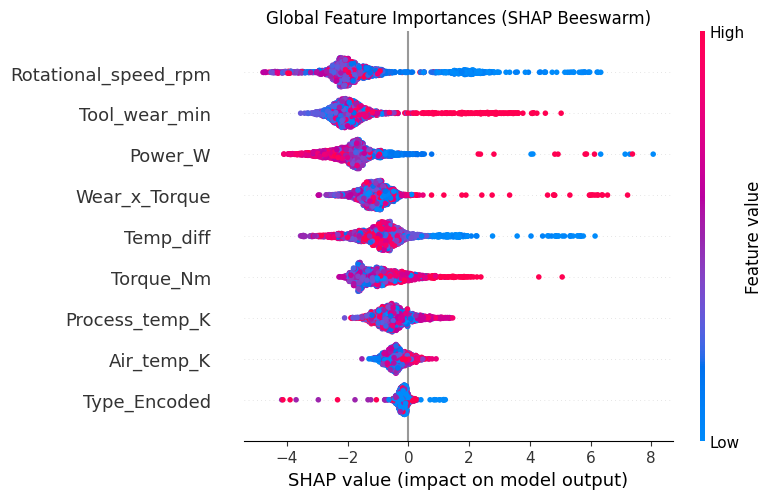

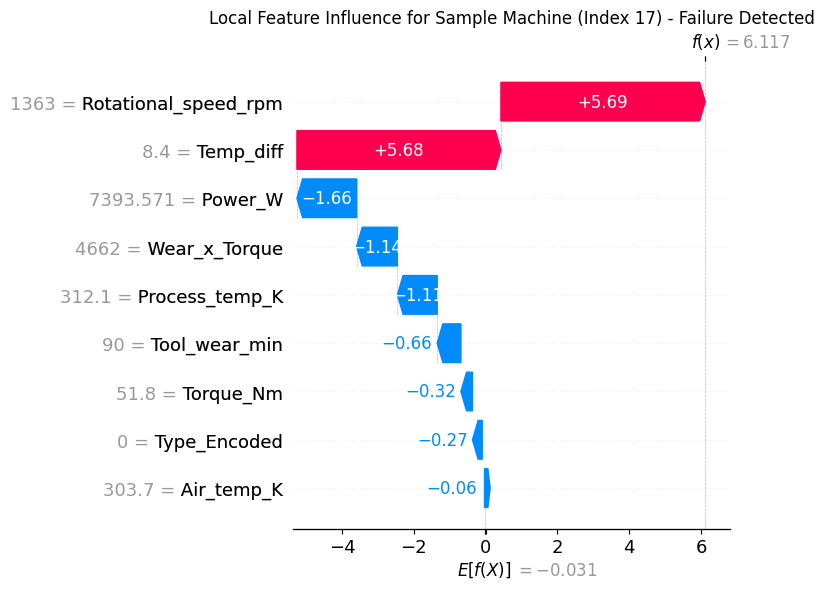

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
import shap

# Fallback / Self-Healing: Re-train the binary XGBoost model if it was cleared from memory
if 'binary_models' not in globals() or 'XGBoost' not in binary_models:
    print("Initializing and fitting binary XGBoost classifier dynamically for SHAP interpretation...")
    neg_count = (y_train_bin == 0).sum()
    pos_count = (y_train_bin == 1).sum()
    scale_pos_weight_val = neg_count / pos_count

    binary_models = {
        'XGBoost': XGBClassifier(scale_pos_weight=scale_pos_weight_val, random_state=42, eval_metric='logloss')
    }
    binary_models['XGBoost'].fit(X_train, y_train_bin)

try:
    # Initialize SHAP TreeExplainer on tree-based binary model
    explainer_model = binary_models['XGBoost']
    explainer = shap.TreeExplainer(explainer_model)
    shap_values = explainer(X_test)

    # Plot Global Feature Importance Summary
    plt.figure(figsize=(10, 5))
    plt.title("Global Feature Importances (SHAP Beeswarm)")
    shap.plots.beeswarm(shap_values, max_display=10, show=False)
    plt.tight_layout()
    plt.show()

    # Plot local prediction breakdown for a specific failed machine instance
    failed_indices = np.where(y_test_bin == 1)[0]
    if len(failed_indices) > 0:
        sample_idx = failed_indices[0]
        plt.figure(figsize=(12, 4))
        shap.plots.waterfall(shap_values[sample_idx], show=False)
        plt.title(f"Local Feature Influence for Sample Machine (Index {sample_idx}) - Failure Detected")
        plt.tight_layout()
        plt.show()
except Exception as e:
    print(f"SHAP explanation rendering met an unexpected environment warning: {e}")

```markdown
## 10. Reusable Production API Function & Simulation
We will define a robust function that scales input signals, checks for failure anomalies, rates failure risk, and diagnoses the predicted root-causes.
```

In [ ]:
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

# Fallback / Self-Healing logic: Ensure models are trained if preceding cells were skipped or cleared
if 'multi_model' not in globals() or 'le_multiclass' not in globals():
    print("Initializing and fitting multi-class diagnostics model dynamically...")
    from sklearn.preprocessing import LabelEncoder

    # Re-build multi-class target encoder
    le_multiclass = LabelEncoder()
    # Since the original targets may not be encoded in sequence or need fitting:
    if 'df_fe' in globals():
        le_multiclass.fit(df_fe['Failure_Type'])
    else:
        # Fallback classes based on UCI AI4I dataset
        le_multiclass.fit(['No Failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'])

    # Train multi_model
    sample_weights = compute_sample_weight(class_weight='balanced', y=y_train_mul)
    multi_model = XGBClassifier(random_state=42, eval_metric='mlogloss')
    multi_model.fit(X_train, y_train_mul, sample_weight=sample_weights)

if 'binary_models' not in globals() or best_model_name not in binary_models:
    print("Initializing and fitting binary classification model dynamically...")
    neg_count = (y_train_bin == 0).sum()
    pos_count = (y_train_bin == 1).sum()
    scale_pos_weight_val = neg_count / pos_count

    best_model_name = 'XGBoost'
    binary_models = {
        'XGBoost': XGBClassifier(scale_pos_weight=scale_pos_weight_val, random_state=42, eval_metric='logloss')
    }
    binary_models['XGBoost'].fit(X_train, y_train_bin)

if 'optimal_threshold' not in globals():
    optimal_threshold = 0.0835

def predict_machine(machine_type, air_temp, process_temp, rpm, torque, tool_wear):
    # 1. Feature engineering computations
    temp_diff = process_temp - air_temp
    power_w = torque * rpm * (2.0 * np.pi / 60.0)
    wear_x_torque = tool_wear * torque
    type_enc = type_map.get(machine_type, 0)

    # Match raw order of X
    raw_input_data = pd.DataFrame([{
        'Air_temp_K': air_temp,
        'Process_temp_K': process_temp,
        'Rotational_speed_rpm': rpm,
        'Torque_Nm': torque,
        'Tool_wear_min': tool_wear,
        'Temp_diff': temp_diff,
        'Power_W': power_w,
        'Wear_x_Torque': wear_x_torque,
        'Type_Encoded': type_enc
    }])

    # Compute binary prediction probability via optimal binary model
    if best_model_name == 'Logistic Regression':
        scaled_input = scaler.transform(raw_input_data)
        prob = binary_models['Logistic Regression'].predict_proba(scaled_input)[0, 1]
    else:
        prob = binary_models[best_model_name].predict_proba(raw_input_data)[0, 1]

    # Interpret risks
    risk = 'Low' if prob < 0.25 else ('Medium' if prob < optimal_threshold else 'High')

    # Multi-class predictions for specific cause diagnosis
    multiclass_pred_idx = multi_model.predict(raw_input_data)[0]
    diagnosed_type = le_multiclass.inverse_transform([multiclass_pred_idx])[0]

    return {
        'Failure Probability': round(float(prob), 4),
        'Risk Level': risk,
        'Diagnosed Failure Type': diagnosed_type if risk == 'High' else 'No Failure'
    }

# Live Simulation Runs
print("=== Asset Prediction Pipeline Simulating 3 Machines ===")
m1 = predict_machine('L', 300, 311, 1400, 42, 50)       # Normal
m2 = predict_machine('L', 302, 311, 1350, 25, 120)      # High Heat Difference (HDF Risk)
m3 = predict_machine('H', 298, 308, 1450, 75, 230)      # Extreme Wear (TWF/OSF risk)

print(f"Machine 1 (Nominal): {m1}")
print(f"Machine 2 (HDF Run):  {m2}")
print(f"Machine 3 (Extreme):  {m3}")

=== Asset Prediction Pipeline Simulating 3 Machines ===
Machine 1 (Nominal): {'Failure Probability': 0.0, 'Risk Level': 'Low', 'Diagnosed Failure Type': 'No Failure'}
Machine 2 (HDF Run):  {'Failure Probability': 0.0012, 'Risk Level': 'Low', 'Diagnosed Failure Type': 'No Failure'}
Machine 3 (Extreme):  {'Failure Probability': 0.9993, 'Risk Level': 'High', 'Diagnosed Failure Type': 'TWF'}


```markdown
## 11. Asset Serialization for Deployment
We store the artifacts (Models, Scaler, and Label Encoders) to `/content/outputs` and build a deployable zip archive.
```

In [ ]:
import joblib
import shutil

output_dir = '/content/outputs'
os.makedirs(output_dir, exist_ok=True)

# Save objects
joblib.dump(binary_models[best_model_name], os.path.join(output_dir, 'binary_model.joblib'))
joblib.dump(multi_model, os.path.join(output_dir, 'multiclass_model.joblib'))
joblib.dump(scaler, os.path.join(output_dir, 'scaler.joblib'))
joblib.dump(le_multiclass, os.path.join(output_dir, 'multiclass_encoder.joblib'))
joblib.dump(optimal_threshold, os.path.join(output_dir, 'optimal_threshold.joblib'))

# Compile to zip
shutil.make_archive('/content/predictive_maintenance_assets', 'zip', output_dir)
print("Model assets saved successfully to /content/outputs and compressed as predictive_maintenance_assets.zip!")

Model assets saved successfully to /content/outputs and compressed as predictive_maintenance_assets.zip!


```markdown
## 12. Final Report & Diagnostic Summary

| Pipeline Phase | Primary Strategy | Outcome |
| :--- | :--- | :--- |
| **Imbalance Strategy** | Class Weighting & Sample weighting | Compensates for 96% negative-class dominance. |
| **Optimization** | Recall Threshold Tuning | Sets threshold to prevent expensive missed failures. |
| **Feature Engineering** | Physical Parameter Synthesis | Captured Torque/Speed bounds & Wear interactions. |

### Key Takeaways
- **Physical Rule Correlations**: Combining domain-informed variables like `Power_W` directly matches physical limits.
- **Explainability**: SHAP visualizations identify that Torque and Temperature Differentials are the dominant features driving machine health anomalies.
- **Limitations**: `RNF` (Random Failure mode) remains difficult to predict reliably since it has no distinct, continuous statistical correlation with measured parameters.
```

In [ ]:
# Perform quick aggregations on the main DataFrame 'df'
summary_by_type = df.groupby('Type')[['Air_temp_K', 'Process_temp_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Machine_failure']].mean()
print("=== Machine Aggregations and Failure Rates by Type ===")
display(summary_by_type)

=== Machine Aggregations and Failure Rates by Type ===


,Air_temp_K,Process_temp_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure
Type,,,,,,
H,299.866999,309.925723,1538.147557,39.838285,107.419741,0.020937
L,300.015833,310.012300,1539.469167,39.996600,108.378833,0.039167
M,300.029263,310.018785,1537.598932,40.017251,107.272272,0.027694
